# Effect of adding SAM / SLM-SAM2, MyoSegmenTUM only

Same per-subject 95% CI methodology as `completed_ci_graphs.ipynb`, but
restricted to the MyoSegmenTUM dataset (water modality) and extended with the
SAM-refined variants of MuscleMap WB and Dafne, so the effect of bolting a
SAM-family model onto an existing algorithm's output can be read directly off
the chart.

**Base algorithms** (same 6 as the main notebook) plus **4 SAM-augmented
variants**, each placed immediately next to its base algorithm:

| Variant | What it does | Raw CSVs |
|---|---|---|
| MuscleMap WB + MedSAM (bbox) | MuscleMap's own segmentation boxes used as MedSAM prompts | `muscle_map_wb_boxes_medsam/results_water` |
| MuscleMap WB + MedSAM (mask) | MuscleMap's logit masks used as MedSAM prompts instead of boxes | `muscle_map_wb_masks_medsam/results_water` |
| MuscleMap WB + SLM-SAM2 | MuscleMap output refined by SLM-SAM2 | `muscle_map_wb+slmsam/results_water` |
| Dafne + MedSAM | Dafne output refined by MedSAM | `dafne_and_medsam/results_water` |

None of these raw per-case CSVs existed on disk before this notebook was
built — the predicted masks (`segs_water/*.npz`) were already there, but the
evaluation-vs-ground-truth step hadn't been run. New `column_compare_*.ipynb`
notebooks were added under each variant's `codes/` folder (mirroring
`dafne_and_medsam/codes/column_compare_dafne_medsam.ipynb`, which already
existed) and executed once to produce them.

Reuses the exact same `get_scan_id()` / `per_subject_dice()` join logic as
`completed_ci_graphs.ipynb` since the underlying CSV formats are identical.

In [7]:
import glob
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats

plt.rcParams.update({
    "font.size": 15, "font.family": "sans-serif",
    "axes.spines.top": False, "axes.spines.right": False,
})

In [25]:
# ── Normalise each CSV's rows to a per-scan id (subject + stack) so muscle
# files are joined on the correct subject rather than on accidental row order.
# Identical to completed_ci_graphs.ipynb.
_SCAN_RE = re.compile(r'([A-Za-z]+\d+_\d+)_(?:WATER|FATFRACTION)_stack(\d+)')
_SCAN_RE_PATH = re.compile(r'[\\/]([A-Za-z]+\d+_\d+)[\\/]SegmentationMasks[\\/]combined_gt_stack(\d+)')


def get_scan_id(d):
    """Return a Series of unique per-row scan ids ('SUBJECT_stackN')."""
    if 'subject' in d.columns and 'stack' in d.columns:
        return d['subject'].astype(str) + '_stack' + d['stack'].astype(str)

    first_col = d.columns[0]
    if first_col != 'Unnamed: 0':
        return d[first_col].astype(str)

    for col in ('pred_label', 'pred_file', 'image', 'gt_path'):
        if col in d.columns:
            matches = d[col].astype(str).apply(
                lambda s: _SCAN_RE.search(s) or _SCAN_RE_PATH.search(s))
            if matches.notna().any():
                return matches.apply(lambda m: f'{m.group(1)}_stack{m.group(2)}' if m else None)

    return d[first_col].astype(str)  # last-resort fallback


def per_subject_dice(folder):
    files = glob.glob(os.path.join(folder, "df_*.csv"))
    merged = None
    for f in files:
        d = pd.read_csv(f)
        dice_cols = [c for c in d.columns if c.endswith("_dice")]
        if not dice_cols:
            continue
        sub = d[dice_cols].copy()
        sub.index = get_scan_id(d)
        merged = sub if merged is None else merged.join(sub, how="outer")
    if merged is None or merged.empty:
        return pd.Series(dtype=float)
    return merged.mean(axis=1).dropna()

In [32]:

# ── Algorithm registry: (label, folder, family, sam_kind) ────────────────────
# 'family' controls bar colour (same palette as paper_graphs_morris.ipynb's
# algo_style); 'sam_kind' controls which hatch pattern marks the bar — each
# SAM/MedSAM flavour gets its own pattern (see HATCHES below) so you can tell
# them apart at a glance instead of every augmented bar looking the same.
ALGOS = [
    ("MuscleMap WB",                 "../muscle_map_wb/codes/results_water",        "MuscleMap WB", None),
    ("MuscleMap WB + MedSAM (bbox)", "../muscle_map_wb_boxes_medsam/results_water", "MuscleMap WB", "medsam_bbox"),
    ("MuscleMap WB + MedSAM (mask)", "../muscle_map_wb_masks_medsam/results_water", "MuscleMap WB", "medsam_mask"),
    ("MuscleMap WB + SLM-SAM2",      "../muscle_map_wb+slmsam/results_water",       "MuscleMap WB", "slmsam2"),
    # ("MuscleMap Thigh",              "../muscle_map_thigh/codes/results_water",     "MuscleMap Thigh", None),
    # ("Multimodal-Multiethnic",       "../multimodal-multiethnic/results/results_water", "Multimodal-Multiethnic", None),
    # ("MedCLIP-SAMv2",                "../medclipsamv2textboxes/results_water",      "MedCLIP-SAMv2", None),
    # ("MuSeg",                        "../museg/results_water",                      "MuSeg", None),
    # ("MuSeg (Dixon)",                "../museg/results_dixon",                      "MuSeg", None),
    ("Dafne",                        "../dafne/results_water",                      "Dafne", None),
    ("Dafne + MedSAM (bbox)",        "../dafne_and_medsam/results_water",           "Dafne", "medsam_bbox"),
    ("Dafne + MedSAM (mask)",        "../dafne_masks_medsam/results_water",         "Dafne", "medsam_mask"),
    ("Dafne + SLM-SAM2",             "../dafne+slmsam/results_water",               "Dafne", "slmsam2"),
]

# One distinct hatch pattern per SAM flavour — same flavour always looks the
# same regardless of which base algorithm it's attached to.
HATCHES = {
    None:          "",     # base algorithm, no hatch
    "medsam_bbox": "//",   # forward hatch
    "medsam_mask": "o",    # polka dots
    "slmsam2":     "\\\\", # backward hatch
}

FAMILY_COLORS = {
    "MuscleMap WB":       "#56B4E9",#    "#0072B2",
    "MuscleMap Thigh":        "#56B4E9",
    "Multimodal-Multiethnic": "#CC79A7",
    "MuSeg":                  "#009E73",
    "MedCLIP-SAMv2":          "#E69F00",
    "Dafne":                  "#009E73",#"#E69F00",#"#D55E00",
}

for label, folder, family, sam_kind in ALGOS:
    print(f'{label:32s} -> {folder}  (family={family}, sam_kind={sam_kind})')

MuscleMap WB                     -> ../muscle_map_wb/codes/results_water  (family=MuscleMap WB, sam_kind=None)
MuscleMap WB + MedSAM (bbox)     -> ../muscle_map_wb_boxes_medsam/results_water  (family=MuscleMap WB, sam_kind=medsam_bbox)
MuscleMap WB + MedSAM (mask)     -> ../muscle_map_wb_masks_medsam/results_water  (family=MuscleMap WB, sam_kind=medsam_mask)
MuscleMap WB + SLM-SAM2          -> ../muscle_map_wb+slmsam/results_water  (family=MuscleMap WB, sam_kind=slmsam2)
Dafne                            -> ../dafne/results_water  (family=Dafne, sam_kind=None)
Dafne + MedSAM (bbox)            -> ../dafne_and_medsam/results_water  (family=Dafne, sam_kind=medsam_bbox)
Dafne + MedSAM (mask)            -> ../dafne_masks_medsam/results_water  (family=Dafne, sam_kind=medsam_mask)
Dafne + SLM-SAM2                 -> ../dafne+slmsam/results_water  (family=Dafne, sam_kind=slmsam2)


In [33]:
ci_stats = {}
missing = []

for label, folder, family, sam_kind in ALGOS:
    if not os.path.isdir(folder):
        missing.append((label, folder))
        continue

    vals = per_subject_dice(folder)
    n = len(vals)
    if n < 2:
        missing.append((label, f'{folder} (n={n}, need >=2 for a CI)'))
        continue

    mean = vals.mean()
    sem = vals.std(ddof=1) / np.sqrt(n)
    halfwidth = stats.t.ppf(0.975, n - 1) * sem
    ci_stats[label] = (mean, halfwidth, n)
    print(f"{label:32s} n={n:3d} mean={mean:.3f} +/- {halfwidth:.3f}")

if missing:
    print(f'\n{len(missing)} algorithm(s) skipped:')
    for label, why in missing:
        print(f'  {label:32s} {why}')

MuscleMap WB                     n= 46 mean=0.825 +/- 0.024
MuscleMap WB + MedSAM (bbox)     n= 46 mean=0.737 +/- 0.027
MuscleMap WB + MedSAM (mask)     n= 46 mean=0.369 +/- 0.038
MuscleMap WB + SLM-SAM2          n= 46 mean=0.380 +/- 0.038
Dafne                            n= 46 mean=0.031 +/- 0.010
Dafne + MedSAM (bbox)            n= 46 mean=0.067 +/- 0.009
Dafne + MedSAM (mask)            n= 46 mean=0.099 +/- 0.018
Dafne + SLM-SAM2                 n= 46 mean=0.010 +/- 0.004


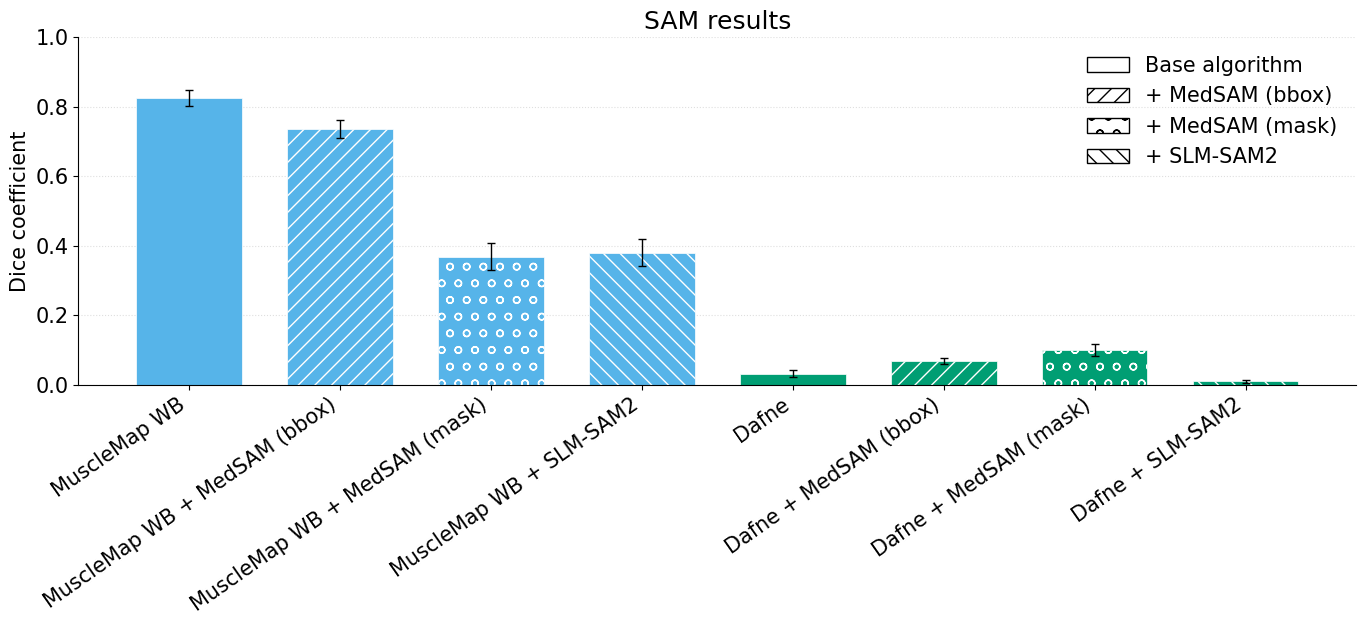

saved dice_bars_ci_with_sam (.png, .pdf, .tiff)


In [34]:
# ---- single-dataset bar chart with 95% CI error bars ----
# Bars are grouped by base algorithm (same colour); each SAM/MedSAM flavour
# gets its own hatch pattern (see HATCHES above) so, e.g., "+ MedSAM (bbox)"
# looks the same everywhere it appears, distinct from "+ MedSAM (mask)" and
# "+ SLM-SAM2" — not just a generic "this bar was SAM-augmented" marker.
plot_algos = [a for a in ALGOS if a[0] in ci_stats]

fig, ax = plt.subplots(figsize=(14, 6.5))
x = np.arange(len(plot_algos))
means = [ci_stats[label][0] for label, *_ in plot_algos]
errs  = [ci_stats[label][1] for label, *_ in plot_algos]
colors = [FAMILY_COLORS[family] for _, _, family, _ in plot_algos]
hatches = [HATCHES[sam_kind] for _, _, _, sam_kind in plot_algos]

for xi, mean, err, color, hatch in zip(x, means, errs, colors, hatches):
    ax.bar(xi, mean, 0.7, yerr=err, capsize=3, color=color, hatch=hatch,
           edgecolor="white", linewidth=0.5, error_kw=dict(ecolor="black", elinewidth=1))

ax.set_xticks(x)
ax.set_xticklabels([label for label, *_ in plot_algos], rotation=35, ha="right")
ax.set_ylabel("Dice coefficient"); ax.set_ylim(0, 1)
ax.set_title("SAM results")
ax.grid(axis="y", linestyle=":", alpha=0.4); ax.set_axisbelow(True)

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Base algorithm"),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch=HATCHES["medsam_bbox"], label="+ MedSAM (bbox)"),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch=HATCHES["medsam_mask"], label="+ MedSAM (mask)"),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch=HATCHES["slmsam2"], label="+ SLM-SAM2"),
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False)

plt.tight_layout()
plt.savefig("dice_bars_ci_with_sam.png", dpi=200, bbox_inches="tight")
plt.savefig("dice_bars_ci_with_sam.pdf", bbox_inches="tight")
plt.savefig("dice_bars_ci_with_sam.tiff", dpi=200, bbox_inches="tight")
plt.show()
print("saved dice_bars_ci_with_sam (.png, .pdf, .tiff)")

In [20]:
# ── Explicit before/after summary ─────────────────────────────────────────────
pairs = [
    ("MuscleMap WB", "MuscleMap WB + MedSAM (bbox)"),
    ("MuscleMap WB", "MuscleMap WB + MedSAM (mask)"),
    ("MuscleMap WB", "MuscleMap WB + SLM-SAM2"),
    ("Dafne", "Dafne + MedSAM (bbox)"),
    ("Dafne", "Dafne + MedSAM (mask)"),
    ("Dafne", "Dafne + SLM-SAM2"),
]
for base, variant in pairs:
    if base in ci_stats and variant in ci_stats:
        base_mean = ci_stats[base][0]
        variant_mean = ci_stats[variant][0]
        delta = variant_mean - base_mean
        direction = "improves" if delta > 0 else "hurts"
        print(f'{variant:32s} {direction} on {base} by {delta:+.3f} dice '
              f'({base_mean:.3f} -> {variant_mean:.3f})')
    elif variant not in ci_stats:
        print(f'{variant:32s} not available yet — see the missing-data list above')

MuscleMap WB + MedSAM (bbox)     hurts on MuscleMap WB by -0.088 dice (0.825 -> 0.737)
MuscleMap WB + MedSAM (mask)     hurts on MuscleMap WB by -0.456 dice (0.825 -> 0.369)
MuscleMap WB + SLM-SAM2          hurts on MuscleMap WB by -0.445 dice (0.825 -> 0.380)
Dafne + MedSAM (bbox)            improves on Dafne by +0.037 dice (0.031 -> 0.067)
Dafne + MedSAM (mask)            not available yet — see the missing-data list above
Dafne + SLM-SAM2                 not available yet — see the missing-data list above
